In [6]:
%pip install gensim==4.4.0


  Using cached smart_open-8.0.2-py3-none-any.whl.metadata (24 kB)
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   - -------------------------------------- 1.0/24.4 MB 5.1 MB/s eta 0:00:05
   --- ------------------------------------ 1.8/24.4 MB 4.2 MB/s eta 0:00:06
   ---- ----------------------------------- 2.6/24.4 MB 4.2 MB/s eta 0:00:06
   ----- ---------------------------------- 3.4/24.4 MB 4.1 MB/s eta 0:00:06
   ------ --------------------------------- 4.2/24.4 MB 4.0 MB/s eta 0:00:05
   -------- ------------------------------- 5.0/24.4 MB 4.0 MB/s eta 0:00:05
   --------- ------------------------------ 6.0/24.4 MB 4.0 MB/s eta 0:00:05
   ----------- ---------------------------- 6.8/24.4 MB 4.0 MB/s eta 0:00:05
   ------------ --------------------------- 7.6/24.4 MB 4.0 MB/s eta 0:00:05
   ------------- -------------------------- 8.4/24.4 MB 3.9 MB/s eta 0:00:05
   --------------- ------------------------ 9.2/24.4 MB 4.0 MB/s eta 0:00:04
   --------------

In [9]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_curve, roc_auc_score, accuracy_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from gensim.models import Word2Vec

In [11]:
data=pd.read_csv(r"C:\Users\sharm\Downloads\Data Set _Question Identification - Data Set __1748351159-5ea65d4bfbba7875acb26a15 (1).csv.csv")

In [13]:
data.shape
data.head(10)

,Unnamed: 0,sentence,label
0,0,Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ b...,sentence
1,1,"Born and raised in Houston, Texas, she perform...",sentence
2,2,"Managed by her father, Mathew Knowles, the gro...",sentence
3,3,Their hiatus saw the release of Beyoncé's debu...,sentence
4,4,Following the disbandment of Destiny's Child i...,sentence
5,5,"Beyoncé also ventured into acting, with a Gold...",sentence
6,6,Her marriage to rapper Jay Z and portrayal of ...,sentence
7,7,Beyoncé took a hiatus from music in 2010 and t...,sentence
8,8,"Her critically acclaimed fifth studio album, B...",sentence
9,9,"A self-described ""modern-day feminist"", Beyonc...",sentence


label
question    131402
sentence    103708
Name: count, dtype: int64


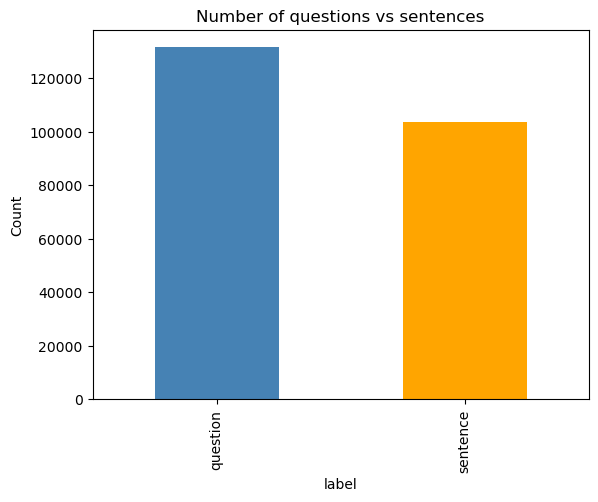

In [ ]:
print(data["label"].value_counts())
data["label"].value_counts().plot(kind="bar", color=["blue", "orange"])
plt.title("Number of questions vs sentences")
plt.ylabel("Count")
plt.show()

In [22]:
data = data.drop(columns=["Unnamed: 0"],errors= 'ignore')
print(data.isna().sum(), "\n")
data=data.dropna()
data = data.drop_duplicates(subset=["sentence", "label"])  # exact duplicates
data = data.drop_duplicates(subset="sentence", keep=False) # same text with 2 different labels
print(len(data))

sentence    0
label       0
dtype: int64 

231104


In [23]:
data["target"] = (data["label"] == "question").astype(int)

In [24]:
data["ends_with_qmark"] = data["sentence"].str.strip().str.endswith("?")
print(pd.crosstab(data["label"], data["ends_with_qmark"]))

ends_with_qmark  False   True 
label                         
question          1859  129375
sentence         99735     135


In [27]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    data["sentence"], data["target"], test_size=0.2, random_state=42, stratify=data["target"])

print("Train size:", len(X_train_raw), "| Test size:", len(X_test_raw))

Train size: 184883 | Test size: 46221


In [28]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+", " ", text)      # remove links
    text = re.sub(r"[^a-z\s]", " ", text)     # remove punctuation and numbers
    text = re.sub(r"\s+", " ", text).strip()  # remove extra spaces
    return text


def remove_stopwords(text):
    return " ".join(w for w in text.split() if w not in ENGLISH_STOP_WORDS)


example = 'Who did Beyonce record with for the movie "The Best Man?"'
print("Original      :", example)
print("Cleaned       :", clean_text(example))
print("No stop words :", remove_stopwords(clean_text(example)))

Original      : Who did Beyonce record with for the movie "The Best Man?"
Cleaned       : who did beyonce record with for the movie the best man
No stop words : did beyonce record movie best man


In [29]:
def quick_auc(train_text, test_text, token_pattern=r"(?u)\b\w\w+\b"):
    vec = TfidfVectorizer(token_pattern=token_pattern)
    Xtr = vec.fit_transform(train_text)
    Xte = vec.transform(test_text)
    model = LogisticRegression(max_iter=1000).fit(Xtr, y_train)
    return roc_auc_score(y_test, model.predict_proba(Xte)[:, 1])


train_clean = X_train_raw.apply(clean_text)
test_clean = X_test_raw.apply(clean_text)

results_cleaning = {
    "A) Raw text, keep ? and punctuation": quick_auc(X_train_raw.str.lower(), X_test_raw.str.lower(), token_pattern=r"\w+|[?]"),
    "B) Cleaned (no punctuation)": quick_auc(train_clean, test_clean),
    "C) Cleaned + stop words removed": quick_auc(train_clean.apply(remove_stopwords), test_clean.apply(remove_stopwords)),
}

pd.Series(results_cleaning, name="ROC-AUC").round(4).to_frame()

,ROC-AUC
"A) Raw text, keep ? and punctuation",0.9989
B) Cleaned (no punctuation),0.9949
C) Cleaned + stop words removed,0.8897


In [30]:
features = {}       # name -> (train matrix, test matrix)
transformers = {}   # name -> function that converts new raw sentences (used at the end)


def add_tfidf_like(name, vectorizer):
    Xtr = vectorizer.fit_transform(train_clean)
    Xte = vectorizer.transform(test_clean)
    features[name] = (Xtr, Xte)
    transformers[name] = lambda raw_list, v=vectorizer: v.transform([clean_text(t) for t in raw_list])
    print(name, "-> train matrix shape:", Xtr.shape)


add_tfidf_like("Bag of Words", CountVectorizer(max_features=20000))
add_tfidf_like("TF-IDF", TfidfVectorizer(max_features=20000))
add_tfidf_like("TF-IDF + n-grams (1,2)", TfidfVectorizer(ngram_range=(1, 2), max_features=50000, min_df=2))
add_tfidf_like("Char n-grams (2-4)", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), max_features=50000, min_df=2))

Bag of Words -> train matrix shape: (184883, 20000)
TF-IDF -> train matrix shape: (184883, 20000)
TF-IDF + n-grams (1,2) -> train matrix shape: (184883, 50000)
Char n-grams (2-4) -> train matrix shape: (184883, 50000)


In [31]:
train_tokens = [s.split() for s in train_clean]
w2v = Word2Vec(train_tokens, vector_size=100, window=5, min_count=2, workers=4, epochs=10, seed=42)

print("Words most similar to 'born':")
for word, score in w2v.wv.most_similar("born", topn=5):
    print("  ", word, round(score, 3))

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Words most similar to 'born':
   married 0.757
   buried 0.649
   crowned 0.63
   grandfather 0.624
   marrying 0.609


In [32]:
def sentence_vector(sentence):
    vectors = [w2v.wv[w] for w in sentence.split() if w in w2v.wv]
    if len(vectors) == 0:
        return np.zeros(100)
    return np.mean(vectors, axis=0)


Xtr_w2v = np.array([sentence_vector(s) for s in train_clean])
Xte_w2v = np.array([sentence_vector(s) for s in test_clean])

features["Word2Vec (average)"] = (Xtr_w2v, Xte_w2v)
transformers["Word2Vec (average)"] = lambda raw_list: np.array([sentence_vector(clean_text(t)) for t in raw_list])
print("Word2Vec -> train matrix shape:", Xtr_w2v.shape)

Word2Vec -> train matrix shape: (184883, 100)


In [33]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(max_iter=5000),
    "Naive Bayes": MultinomialNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
}

results = []        # one row per (features, model)
roc_data = {}       # for plotting
fitted = {}         # to reuse the best model later

for feat_name, (Xtr, Xte) in features.items():
    is_dense = isinstance(Xtr, np.ndarray)

    for model_name, base_model in models.items():
        if model_name == "Naive Bayes" and is_dense:
            continue                      # Word2Vec has negative numbers
        if model_name == "Random Forest" and not is_dense:
            continue                      # too slow on big sparse matrices

        model = clone(base_model)
        model.fit(Xtr, y_train)

        y_pred = model.predict(Xte)
        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(Xte)[:, 1]
        else:
            y_score = model.decision_function(Xte)

        auc = roc_auc_score(y_test, y_score)
        results.append({"Features": feat_name, "Model": model_name,
                        "Accuracy": accuracy_score(y_test, y_pred),
                        "F1": f1_score(y_test, y_pred),
                        "ROC-AUC": auc})
        roc_data[(feat_name, model_name)] = roc_curve(y_test, y_score)
        fitted[(feat_name, model_name)] = model
        print("done:", feat_name, "|", model_name, "| AUC =", round(auc, 4))

done: Bag of Words | Logistic Regression | AUC = 0.9951
done: Bag of Words | Linear SVM | AUC = 0.9931
done: Bag of Words | Naive Bayes | AUC = 0.9853
done: TF-IDF | Logistic Regression | AUC = 0.9951
done: TF-IDF | Linear SVM | AUC = 0.995
done: TF-IDF | Naive Bayes | AUC = 0.9594
done: TF-IDF + n-grams (1,2) | Logistic Regression | AUC = 0.9965
done: TF-IDF + n-grams (1,2) | Linear SVM | AUC = 0.997
done: TF-IDF + n-grams (1,2) | Naive Bayes | AUC = 0.9823
done: Char n-grams (2-4) | Logistic Regression | AUC = 0.9952
done: Char n-grams (2-4) | Linear SVM | AUC = 0.9956
done: Char n-grams (2-4) | Naive Bayes | AUC = 0.9697
done: Word2Vec (average) | Logistic Regression | AUC = 0.9903
done: Word2Vec (average) | Linear SVM | AUC = 0.9901
done: Word2Vec (average) | Random Forest | AUC = 0.9885


In [34]:
results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
results_df.round(4)

,Features,Model,Accuracy,F1,ROC-AUC
0,"TF-IDF + n-grams (1,2)",Linear SVM,0.9835,0.9854,0.9970
1,"TF-IDF + n-grams (1,2)",Logistic Regression,0.9809,0.9831,0.9965
2,Char n-grams (2-4),Linear SVM,0.9781,0.9807,0.9956
3,Char n-grams (2-4),Logistic Regression,0.9766,0.9793,0.9952
4,Bag of Words,Logistic Regression,0.9767,0.9794,0.9951
5,TF-IDF,Logistic Regression,0.9765,0.9793,0.9951
6,TF-IDF,Linear SVM,0.9766,0.9794,0.9950
7,Bag of Words,Linear SVM,0.9710,0.9744,0.9931
8,Word2Vec (average),Logistic Regression,0.9683,0.9719,0.9903
9,Word2Vec (average),Linear SVM,0.9688,0.9723,0.9901


Best combination: TF-IDF + n-grams (1,2) + Linear SVM
ROC-AUC: 0.997 | Accuracy: 0.9835 | F1: 0.9854

              precision    recall  f1-score   support

    sentence       0.98      0.98      0.98     19974
    question       0.99      0.98      0.99     26247

    accuracy                           0.98     46221
   macro avg       0.98      0.98      0.98     46221
weighted avg       0.98      0.98      0.98     46221



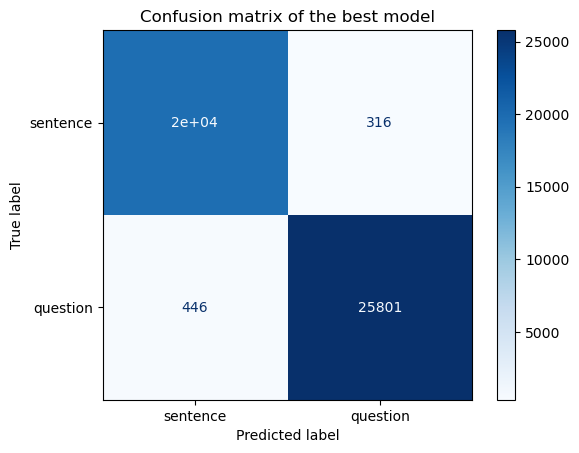

In [36]:
best = results_df.iloc[0]
best_key = (best["Features"], best["Model"])
print("Best combination:", best["Features"], "+", best["Model"])
print("ROC-AUC:", round(best["ROC-AUC"], 4), "| Accuracy:", round(best["Accuracy"], 4), "| F1:", round(best["F1"], 4))

best_model = fitted[best_key]
best_Xte = features[best["Features"]][1]
y_pred_best = best_model.predict(best_Xte)

print()
print(classification_report(y_test, y_pred_best, target_names=["sentence", "question"]))

cm = confusion_matrix(y_test, y_pred_best)
ConfusionMatrixDisplay(cm, display_labels=["sentence", "question"]).plot(cmap="Blues")
plt.title("Confusion matrix of the best model")
plt.show()

In [37]:
errors = pd.DataFrame({"sentence": X_test_raw.values, "actual": y_test.values, "predicted": y_pred_best})
errors = errors[errors["actual"] != errors["predicted"]]
print("Total mistakes:", len(errors), "out of", len(y_test))
errors["actual"] = errors["actual"].map({0: "sentence", 1: "question"})
errors["predicted"] = errors["predicted"].map({0: "sentence", 1: "question"})
errors.head(10)

Total mistakes: 762 out of 46221


,sentence,actual,predicted
42,"Only certified applicators, who have passed an...",sentence,question
107,not any more 10-19-20sUser115,sentence,question
143,Are prices at these outlets generally higher o...,question,sentence
236,girl take make u do,sentence,question
244,Did literate men acknowledge Virgil as a maste...,question,sentence
267,Proponents of permanent DST say it has all the...,question,sentence
497,Who made it for such little cost?,sentence,question
541,AGi32or Dialux).,sentence,question
577,"A female dragon named Delphyne (δελφύς, ""womb""...",sentence,question
634,The bill removed political power from plantati...,sentence,question


In [38]:
new_sentences = [
    "What is the difference between a list and a tuple?",
    "Today we will learn about linked lists.",
    "How does gradient descent update the weights",
    "The model is trained for ten epochs.",
    "Can anyone tell me why the loss is increasing",
    "Remember to submit the assignment before Friday.",
]

X_new = transformers[best["Features"]](new_sentences)
predictions = best_model.predict(X_new)

for sentence, p in zip(new_sentences, predictions):
    print(("QUESTION" if p == 1 else "sentence"), "|", sentence)

QUESTION | What is the difference between a list and a tuple?
sentence | Today we will learn about linked lists.
QUESTION | How does gradient descent update the weights
sentence | The model is trained for ten epochs.
QUESTION | Can anyone tell me why the loss is increasing
sentence | Remember to submit the assignment before Friday.
